In [177]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np


In [178]:
DATA_PATH = Path("../../data/raw/SMSSpamCollection")

df = pd.read_csv(
    DATA_PATH,
    sep="\t",
    header=None,
    names=["label", "message"],
)

In [179]:
print("First rows:")
print(df.head())

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing values:")
print(df.isna().sum())

First rows:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Shape:
(5572, 2)

Columns:
Index(['label', 'message'], dtype='str')

Missing values:
label      0
message    0
dtype: int64


In [180]:
#   Check duplicates in the original dataset
duplicate_rows = df.duplicated().sum()

duplicate_messages = df.duplicated(subset=["message"]).sum()

print(f"Exact duplicate rows: {duplicate_rows}")
print(f"Duplicate messages:   {duplicate_messages}")


Exact duplicate rows: 403
Duplicate messages:   403


In [181]:
label_counts_per_message = df.groupby("message")["label"].nunique()

conflicting_messages = label_counts_per_message[label_counts_per_message > 1]

print(f"Messages with conflicting labels: {len(conflicting_messages)}")


Messages with conflicting labels: 0


In [ ]:
#  clean duplicates in the dataset
df_clean = df.drop_duplicates(subset=["message"]).reset_index(drop=True)

In [ ]:
X = df_clean["message"] # remove duplicate messages and reset the index
y = df_clean["label"] # remove duplicate labels and reset the index

print("\nX:")
print(X.head())

print("\ny:")
print(y.head())


X:
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: str

y:
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: str


In [184]:
class_counts = df["label"].value_counts()

print("\nClass counts:")
print(class_counts)


Class counts:
label
ham     4825
spam     747
Name: count, dtype: int64


In [185]:
class_percentages = (
    df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nClass percentages:")
print(class_percentages)


Class percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


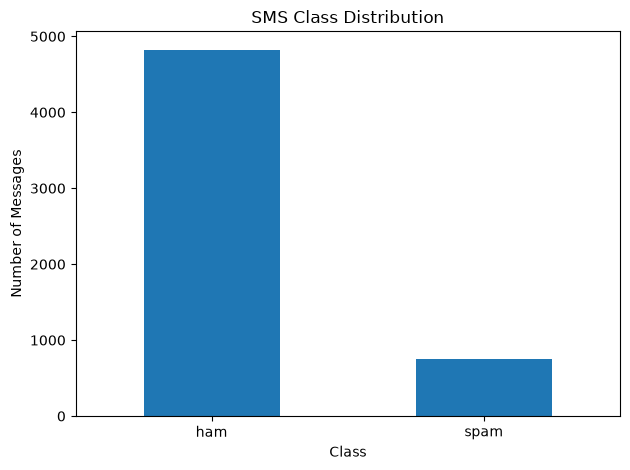

In [186]:
import matplotlib.pyplot as plt

class_counts.plot(kind="bar")

plt.title("SMS Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [187]:
# split off 20%:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [188]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp,
)

In [189]:
train_messages = set(X_train)
val_messages = set(X_val)
test_messages = set(X_test)

train_val_overlap = train_messages & val_messages

train_test_overlap = train_messages & test_messages

val_test_overlap = val_messages & test_messages

print(
    "Train ↔ Validation overlap:",
    len(train_val_overlap),
)

print(
    "Train ↔ Test overlap:",
    len(train_test_overlap),
)

print(
    "Validation ↔ Test overlap:",
    len(val_test_overlap),
)


Train ↔ Validation overlap: 0
Train ↔ Test overlap: 0
Validation ↔ Test overlap: 0


In [190]:
conflicting_rows = df[df["message"].isin(conflicting_messages.index)]

print(conflicting_rows.sort_values("message").to_string(index=False))


Empty DataFrame
Columns: [label, message]
Index: []


In [191]:
print(f"Train size: {len(X_train)}")
print(f"Validation size: {len(X_val)}")
print(f"Test size: {len(X_test)}")

Train size: 4135
Validation size: 517
Test size: 517


In [192]:
print(f"Test size: {len(X_test)}")

Test size: 517


In [193]:
print("\nTrain distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True))

print("\nTest distribution:")
print(y_test.value_counts(normalize=True))


Train distribution:
label
ham     0.873761
spam    0.126239
Name: proportion, dtype: float64

Validation distribution:
label
ham     0.87234
spam    0.12766
Name: proportion, dtype: float64

Test distribution:
label
ham     0.874275
spam    0.125725
Name: proportion, dtype: float64


In [194]:

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

majority_class = y_train.mode()[0]

baseline_predictions = np.full(
    shape=len(y_val),
    fill_value=majority_class,
)

In [195]:
y_train.mode()[0]

'ham'

In [196]:

baseline_accuracy = accuracy_score(
    y_val,
    baseline_predictions, 
)

baseline_f1 = f1_score(
    y_val,
    baseline_predictions,
    pos_label="spam",
)

print("\nMajority baseline:")
print(f"Accuracy: {baseline_accuracy:.4f}")
print(f"F1:       {baseline_f1:.4f}")


Majority baseline:
Accuracy: 0.8723
F1:       0.0000


In [197]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
print(X_train_tfidf)

X_val_tfidf = vectorizer.transform(X_val)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 54735 stored elements and shape (4135, 7680)>
  Coords	Values
  (0, 6620)	0.46972053147573545
  (0, 2121)	0.5494390936793128
  (0, 926)	0.27302453527471554
  (0, 3431)	0.28681222213960167
  (0, 1175)	0.32889978169730083
  (0, 1034)	0.22262669782699995
  (0, 7644)	0.14137598054893938
  (0, 6426)	0.2883706884664802
  (0, 7123)	0.24452632207532418
  (1, 7666)	0.3692015439831947
  (1, 3316)	0.36341476387791166
  (1, 4613)	0.19995964613324727
  (1, 4210)	0.37125568141268966
  (1, 1543)	0.5155024572995014
  (1, 4791)	0.21735204696568938
  (1, 2482)	0.37125568141268966
  (1, 915)	0.3209202571821429
  (2, 7644)	0.15846316312851633
  (2, 4869)	0.2845838793573964
  (2, 992)	0.4276147771423104
  (2, 4742)	0.2694958804038539
  (2, 4672)	0.3164797385708495
  (2, 6871)	0.15667199372011065
  (2, 1720)	0.4632054417386278
  (2, 7483)	0.2708972072041858
  :	:
  (4133, 6756)	0.15752910004873982
  (4133, 3112)	0.11975193769214103
  (4133, 3715)

In [ ]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced", # use balanced class weights to handle class imbalance
)
model.fit(
    X_train_tfidf,
    y_train,
)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [199]:
import joblib

ARTIFACTS_DIR = Path("../../artifacts")

VECTORIZER_PATH = ARTIFACTS_DIR / "vectorizer.joblib"
MODEL_PATH = ARTIFACTS_DIR / "model.joblib"

ARTIFACTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)
# Save to model and vectorizer
joblib.dump(
    vectorizer,
    VECTORIZER_PATH,
)

joblib.dump(
    model,
    MODEL_PATH,
)


['..\\..\\artifacts\\model.joblib']

In [200]:
val_predictions = model.predict(X_val_tfidf)

In [201]:
model_accuracy = accuracy_score(
    y_val,
    val_predictions,
)

model_f1 = f1_score(
    y_val,
    val_predictions,
    pos_label="spam",
)

print("\nTF-IDF + Logistic Regression:")
print(f"Accuracy: {model_accuracy:.4f}")
print(f"F1:       {model_f1:.4f}")


TF-IDF + Logistic Regression:
Accuracy: 0.9652
F1:       0.8448


In [202]:
precision = precision_score(
    y_val,
    val_predictions,
    pos_label="spam",
)

In [203]:
model_recall = recall_score(
    y_val,
    val_predictions,
    pos_label="spam",
)

In [204]:
print("\nMetrics:")
print(f"Accuracy:  {model_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {model_recall:.4f}")
print(f"F1:        {model_f1:.4f}")


Metrics:
Accuracy:  0.9652
Precision: 0.9800
Recall:    0.7424
F1:        0.8448


In [205]:
cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=[ "ham", "spam"],
)
print("\nConfusion matrix:")
print(cm)


Confusion matrix:
[[450   1]
 [ 17  49]]


In [206]:
results = pd.DataFrame(
    {
        "message": X_val,
        "actual": y_val,
        "predicted": val_predictions,
    }
).reset_index(drop=True)


In [207]:
false_positives = results[
    (results["actual"] == "ham")
    & (results["predicted"] == "spam")
]

false_negatives = results[
    (results["actual"] == "spam")
    & (results["predicted"] == "ham")
]


In [208]:
print(f"\nFalse positives: {len(false_positives)}")
print(f"False negatives: {len(false_negatives)}")

print("\nFalse positives:")
print(false_positives.head(10).to_string(index=False))

print("\nFalse negatives:")
print(false_negatives.head(10).to_string(index=False))


False positives: 1
False negatives: 17

False positives:
                                                                                                                     message actual predicted
I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to  &lt;#&gt;    ham      spam

False negatives:
                                                                                                                                                         message actual predicted
              In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)   spam       ham
                                                                                                                               88066 FROM 88066 LOST 3POUND HELP   spam       ham
                                                                               Bought one ringtone and now